# 09 - Are Claims in Lower-Income Neighbourhoods Treated Differently?

**DSC 411/511 Semester Project** · Venkat Repaka, Ritik Gaire

**Question:** Are flood claims in **lower-income neighbourhoods** paid less, or closed without payment more often, than claims **with the
same damage** in richer neighbourhoods?

**Why this question?** Earlier studies found that claims in whiter or richer areas received more and were less often unpaid
(Urban Institute, New Orleans; Kraft et al. 2025, Houston), but they did not compare claims with the **same damage**. Our data has the
damage ratio (notebook 01), so we can make that fairer comparison, for 2020-2025 and for all regions. Notebook 08 also showed that
cheaper homes are underinsured more often, which is a first hint.

**Census data.** We add three numbers for the **census block group** of each claim (a neighbourhood of about 600-3,000 people), from the
**American Community Survey (ACS) 2020-2024 5-year estimates** of the US Census Bureau: median household income, median home value and
share of renters. The script `build_census_features.py` downloads them once into `data/acs_blockgroups.parquet`.

**Important:** these are numbers about the **neighbourhood**, not about the person who made the claim. We can say "claims in low-income
neighbourhoods...", but not "low-income people...".

**Plan**
1. Join the census data to the claims
2. Where do the claims come from? (income groups)
3. Raw comparison: payment, non-payment, damage and underinsurance by income
4. Fair comparison: the same damage, zone, building, storm and place
5. Our answer

## 1. Join the census data to the claims

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
SEED = 42

df = pd.read_parquet('data/claims_clean.parquet')
raw = pd.read_parquet('/Users/home/workspace/School/DataMining/project/NfipClaimsV3.parquet',
                      columns=['id', 'censusGeoid', 'buildingReplacementCost', 'nonPaymentReasonBuilding'])
df = df.merge(raw, on='id', how='left')
acs = pd.read_parquet('data/acs_blockgroups.parquet')
df = df.merge(acs, on='censusGeoid', how='left')

df['matched'] = df['median_household_income'].notna()
print(f"Claims: {len(df):,}")
print(f"   with a block group code          : {df['censusGeoid'].notna().mean():.1%}")
print(f"   matched to a census income value : {df['matched'].mean():.1%}")
print('\nMatched share by loss year:')
print((df.groupby('loss_year')['matched'].mean() * 100).round(1).to_string())

Claims: 276,570
   with a block group code          : 99.1%
   matched to a census income value : 85.0%

Matched share by loss year:
loss_year
2020    75.8
2021    78.9
2022    83.8
2023    86.2
2024    90.6
2025    89.5


**Why are some claims not matched?** The census changes the block group codes every 10 years. Our census data uses the **2020** codes.
Older claims (2020-2021) more often still have **2010** codes, so they match less often. Some block groups also have no income value
(the Census does not publish it when there are too few households). We use the matched claims only and keep this in mind.

## 2. Where do the claims come from?

We split **all US block groups** into five equal groups by median household income (**national income quintiles**), so "Q1" means the
poorest 20% of neighbourhoods in the whole country and "Q5" the richest 20%. If claims came equally from all neighbourhoods, each quintile
would have 20% of the claims.

Income limits of the national quintiles ($): ['52,250', '70,536', '90,245', '121,667']


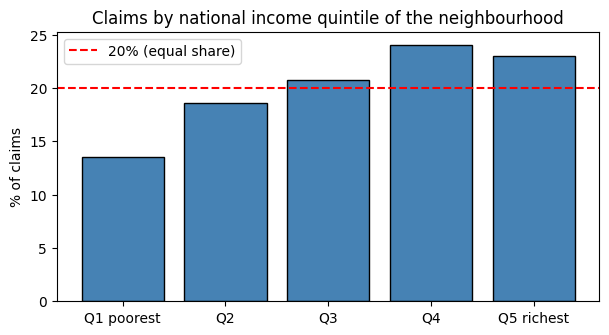

income_q
Q1 poorest    13.5
Q2            18.6
Q3            20.7
Q4            24.1
Q5 richest    23.0

Florida share of the claims in each quintile:
income_q
Q1 poorest    47.2
Q2            52.4
Q3            56.7
Q4            61.3
Q5 richest    61.7


In [2]:
edges = acs['median_household_income'].quantile([0, 0.2, 0.4, 0.6, 0.8, 1.0]).values
edges[0], edges[-1] = -np.inf, np.inf
Q = ['Q1 poorest', 'Q2', 'Q3', 'Q4', 'Q5 richest']
df['income_q'] = pd.cut(df['median_household_income'], bins=edges, labels=Q)
print('Income limits of the national quintiles ($):', [f'{e:,.0f}' for e in acs['median_household_income'].quantile([0.2, 0.4, 0.6, 0.8])])

m = df[df['matched']].copy()
share = m['income_q'].value_counts(normalize=True).reindex(Q)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(Q, share.values * 100, color='steelblue', edgecolor='black'); ax.axhline(20, color='red', ls='--', label='20% (equal share)')
ax.set_ylabel('% of claims'); ax.set_title('Claims by national income quintile of the neighbourhood'); ax.legend(); plt.show()
print((share * 100).round(1).to_string())
print(f"\nFlorida share of the claims in each quintile:")
print((m.groupby('income_q', observed=True)['state'].apply(lambda s: (s == 'FL').mean()) * 100).round(1).to_string())

**What we see**
- The national income quintiles are: Q1 under $52,250 median household income, Q2 up to $70,536, Q3 up to $90,245, Q4 up to $121,667, Q5 above.
- **Claims come less often from poor neighbourhoods.** Only **13.5%** of the claims are in the poorest fifth of US neighbourhoods, but
  **23-24%** are in each of the two richest fifths.
- Part of this is **place**: richer quintiles have more Florida claims (62% in Q5 vs 47% in Q1), and coastal Florida homes are often in richer
  areas. Part may be that people in poorer areas **buy flood insurance less often**, as other studies found; with claims data only we cannot
  separate these two reasons.

## 3. Raw comparison by income

For each income quintile we look at five things:
- **closed without payment:** the share of claims with no building payment;
- **payment ÷ damage:** for claims with damage, the share of the damage that was paid (the rest is the deductible and the part above the coverage);
- **damage ratio:** how badly the building was damaged (damage ÷ building value);
- **underinsured by choice:** homes with coverage below 80% of the replacement cost **and** below the NFIP limit (definition from notebook 08);
- **median building value** in the claims.

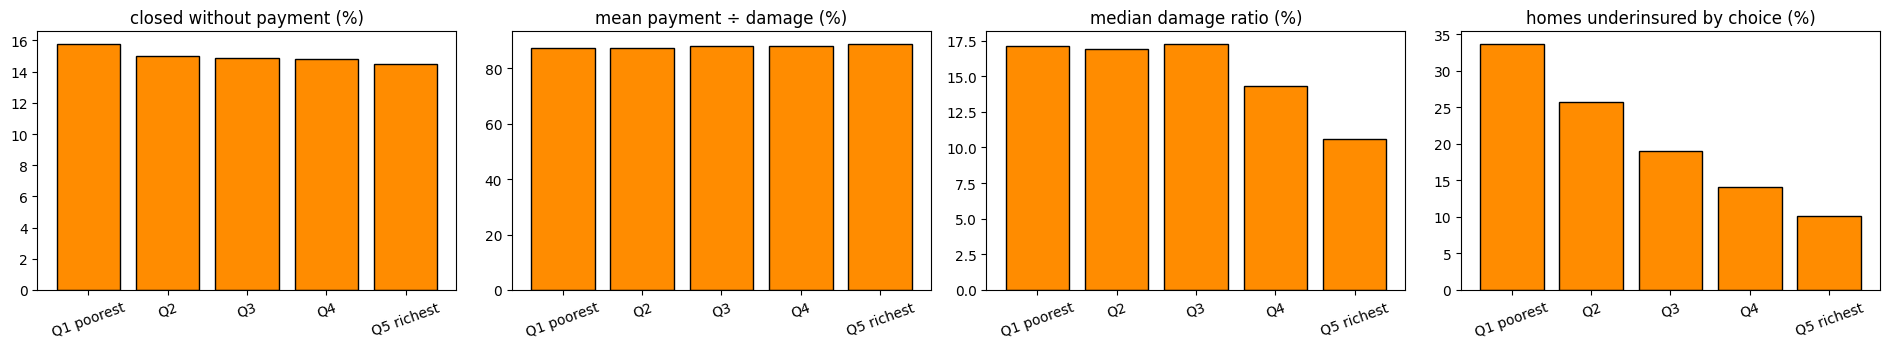

,claims,closed_without_payment,median_pay_ratio,mean_pay_ratio,median_damage_ratio,underinsured_by_choice,median_building_value
income_q,,,,,,,
Q1 poorest,"31,720",15.8%,0.94,0.87,0.171,33.7%,"$161,643"
Q2,"43,827",15.0%,0.95,0.87,0.169,25.8%,"$174,446"
Q3,"48,725",14.9%,0.96,0.88,0.173,19.0%,"$199,757"
Q4,"56,594",14.8%,0.95,0.88,0.143,14.1%,"$222,108"
Q5 richest,"54,169",14.5%,0.96,0.89,0.106,10.1%,"$270,260"


In [3]:
m['not_paid'] = (m['amountPaidOnBuildingClaim'] <= 0).astype(int)
has_damage = m['buildingDamageAmount'] > 0
m['pay_ratio'] = (m['amountPaidOnBuildingClaim'] / m['buildingDamageAmount'].where(has_damage)).clip(upper=1.5)

occ = pd.to_numeric(m['occupancy'], errors='coerce')
home = occ.isin([11, 12, 14, 16])
itv = m['totalBuildingInsuranceCoverage'] / m['buildingReplacementCost'].where(m['buildingReplacementCost'] > 0)
m['under_by_choice'] = np.where(home & itv.notna(), ((itv < 0.8) & (m['totalBuildingInsuranceCoverage'] < 250_000 - 1)).astype(float), np.nan)

raw_table = m.groupby('income_q', observed=True).agg(
    claims=('id', 'size'), closed_without_payment=('not_paid', 'mean'), median_pay_ratio=('pay_ratio', 'median'),
    mean_pay_ratio=('pay_ratio', 'mean'), median_damage_ratio=('damage_ratio', 'median'),
    underinsured_by_choice=('under_by_choice', 'mean'), median_building_value=('buildingPropertyValue', 'median'))
fig, ax = plt.subplots(1, 4, figsize=(19, 3.6))
for a, col, title in [(ax[0], 'closed_without_payment', 'closed without payment'), (ax[1], 'mean_pay_ratio', 'mean payment ÷ damage'),
                      (ax[2], 'median_damage_ratio', 'median damage ratio'), (ax[3], 'underinsured_by_choice', 'homes underinsured by choice')]:
    a.bar(range(5), raw_table[col].values * 100, color='darkorange', edgecolor='black'); a.set_xticks(range(5), Q, rotation=20)
    a.set_title(f'{title} (%)')
plt.tight_layout(); plt.show()
raw_table.style.format({'claims': '{:,.0f}', 'closed_without_payment': '{:.1%}', 'median_pay_ratio': '{:.2f}', 'mean_pay_ratio': '{:.2f}',
                        'median_damage_ratio': '{:.3f}', 'underinsured_by_choice': '{:.1%}', 'median_building_value': '${:,.0f}'})

In [4]:
print('Top reasons for no building payment, by income quintile (% of the unpaid claims in the quintile):')
reasons = m[m['not_paid'] == 1]
top = reasons['nonPaymentReasonBuilding'].value_counts().head(5).index
(pd.crosstab(reasons['income_q'], reasons['nonPaymentReasonBuilding'].where(reasons['nonPaymentReasonBuilding'].isin(top), 'other'),
             normalize='index') * 100).round(1)

Top reasons for no building payment, by income quintile (% of the unpaid claims in the quintile):


nonPaymentReasonBuilding,01,06,20,97,99,other
income_q,,,,,,
Q1 poorest,16.2,25.5,9.4,14.2,16.2,18.5
Q2,19.7,20.5,10.8,13.8,17.8,17.4
Q3,19.4,20.0,11.2,13.1,18.0,18.3
Q4,18.0,17.7,12.1,14.7,17.9,19.6
Q5 richest,16.2,17.2,11.2,15.7,17.7,21.9


**What we see** (raw numbers, nothing held the same yet)

| | Q1 poorest | Q5 richest |
|---|---|---|
| closed without payment | 15.8% | 14.5% |
| payment ÷ damage (mean) | 0.862 | 0.877 |
| median damage ratio | 0.171 | 0.106 |
| homes underinsured by choice | **33.7%** | **10.1%** |
| median building value | $161,643 | $270,260 |

- **The biggest difference is underinsurance:** homes in the poorest neighbourhoods are underinsured by choice **3.3 times** more often
  than in the richest ones (33.7% vs 10.1%). It goes down step by step from Q1 to Q5.
- **Damage:** buildings in the three poorer quintiles lose about 17% of their value (median), the richest only about 11%.
- **Payment and non-payment differ only a little:** 1.3 points more claims closed without payment in Q1, and 1.5 points less of the damage paid.
- **Why claims are not paid:** reason code **06 ("not an actual flood")** is the most common reason in the poorest quintile (25.5% of their
  unpaid claims vs 17.2% in the richest). Code 01 ("below the deductible") and 20 ("no damage that can be shown") are similar in all quintiles.
  We cannot tell from the data *why* more claims in poor areas are judged "not a flood" (for example rain or wind damage instead of flood water).

## 4. Fair comparison: the same damage, zone, building, storm and place

The raw numbers mix many things: poorer and richer neighbourhoods are in **different states**, hit by **different storms**, with **different
buildings**. To compare claims that are alike, we fit a model and then ask: *if every claim were in income quintile Q1 (and then Q2, ...
Q5), what would the average be?* This is called an **adjusted** value: everything else stays the same, only the income group changes.

We use two models for each outcome:
- **Model A (flood and building):** income quintile + damage ratio band + flood zone + foundation + occupancy + building age + storm + state + loss year.
- **Model B (+ insurance choices):** Model A + coverage ÷ replacement cost + deductible.

If a gap is in Model A but disappears in Model B, it is explained by the **insurance people bought**, not by how the claims were handled.
- **Model C (+ damage in dollars), payment only:** Model B + log10 of the building damage in dollars. Cheaper buildings have fewer dollars
  of damage at the same damage ratio, and a fixed deductible (for example $2,000) is a bigger share of a small claim. If the gap disappears
  in Model C, it is this **deductible arithmetic**, not a different treatment of the claims.

For **payment ÷ damage** we use a linear regression on claims with damage. For **closed without payment** we use a logistic regression
(without the damage band, because many unpaid claims have no damage figure).

In [5]:
from sklearn.linear_model import LinearRegression, LogisticRegression

top_states = m['state'].value_counts().head(10).index
top_storms = m['floodEvent'].value_counts().head(12).index
m['state_group'] = m['state'].where(m['state'].isin(top_states), 'other')
m['storm'] = m['floodEvent'].where(m['floodEvent'].isin(top_storms), 'other / none')
m['itv_band'] = pd.cut(itv, [-np.inf, 0.5, 0.8, 1.0, np.inf], labels=['under 50%', '50-80%', '80-100%', 'over 100%']).astype(str)
m['deductible_band'] = pd.cut(m['deductible_usd'], [-1, 1000, 1500, 2000, 5000, np.inf], labels=['<=1000', '1250-1500', '2000', '5000', '>5000']).astype(str)

BASE = ['income_q', 'zone', 'foundation', 'occupancy', 'state_group', 'storm', 'loss_year']
def design(data, extra):
    X = pd.get_dummies(data[BASE + extra].astype({'loss_year': str}), dtype=float)
    X['building_age'] = data['building_age'].values
    return X

def adjusted(model, X):
    out = {}
    qcols = [c for c in X.columns if c.startswith('income_q_')]
    for q in Q:
        Xq = X.copy(); Xq[qcols] = 0.0; Xq[f'income_q_{q}'] = 1.0
        p = model.predict_proba(Xq)[:, 1] if hasattr(model, 'predict_proba') else model.predict(Xq)
        out[q] = p.mean()
    return pd.Series(out)

# Payment / damage, claims with damage and a damage ratio
pdata = m[m['pay_ratio'].notna() & m['severity_band'].notna()].copy()
XA = design(pdata, ['severity_band'])
XB = design(pdata, ['severity_band', 'itv_band', 'deductible_band'])
pay_A = adjusted(LinearRegression().fit(XA, pdata['pay_ratio']), XA)
pay_B = adjusted(LinearRegression().fit(XB, pdata['pay_ratio']), XB)
XC = XB.copy(); XC['log_damage'] = np.log10(pdata['buildingDamageAmount'].values)
pay_C = adjusted(LinearRegression().fit(XC, pdata['pay_ratio']), XC)

# Closed without payment, all matched claims
ndata = m.copy()
XA2 = design(ndata, [])
XB2 = design(ndata, ['itv_band', 'deductible_band'])
def logit(X, y):
    return LogisticRegression(max_iter=2000, C=1.0).fit(X / X.abs().max().replace(0, 1), y), X.abs().max().replace(0, 1)
lA, sA = logit(XA2, ndata['not_paid']); lB, sB = logit(XB2, ndata['not_paid'])
np_A = adjusted(lA, XA2 / sA); np_B = adjusted(lB, XB2 / sB)

result = pd.DataFrame({'payment ÷ damage, raw mean': pdata.groupby('income_q', observed=True)['pay_ratio'].mean(),
                       'payment ÷ damage, model A': pay_A, 'payment ÷ damage, model B': pay_B, 'payment ÷ damage, model C': pay_C,
                       'not paid, raw': ndata.groupby('income_q', observed=True)['not_paid'].mean(),
                       'not paid, model A': np_A, 'not paid, model B': np_B})
print(f'Claims in the payment model: {len(pdata):,}    in the non-payment model: {len(ndata):,}')
gap = result.loc['Q5 richest'] - result.loc['Q1 poorest']
result.loc['gap Q5 - Q1'] = gap
result.round(3)

Claims in the payment model: 176,314    in the non-payment model: 235,035


,"payment ÷ damage, raw mean","payment ÷ damage, model A","payment ÷ damage, model B","payment ÷ damage, model C","not paid, raw","not paid, model A","not paid, model B"
Q1 poorest,0.862,0.858,0.856,0.870,0.158,0.153,0.155
Q2,0.862,0.857,0.859,0.870,0.150,0.147,0.151
Q3,0.870,0.864,0.865,0.867,0.149,0.150,0.151
Q4,0.869,0.870,0.871,0.867,0.148,0.149,0.147
Q5 richest,0.877,0.887,0.885,0.870,0.145,0.148,0.145
gap Q5 - Q1,0.015,0.030,0.030,0.000,-0.013,-0.004,-0.010


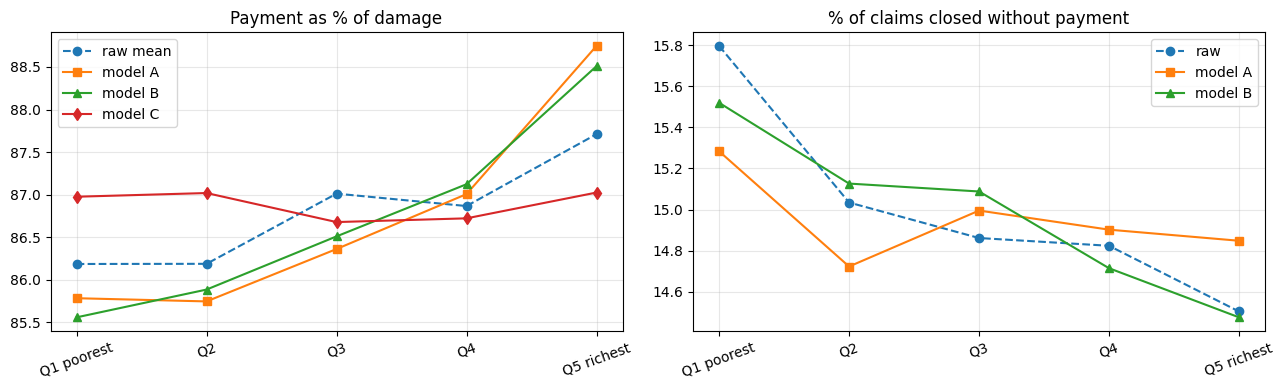

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for col, style in [('payment ÷ damage, raw mean', 'o--'), ('payment ÷ damage, model A', 's-'), ('payment ÷ damage, model B', '^-'), ('payment ÷ damage, model C', 'd-')]:
    ax[0].plot(Q, result.loc[Q, col] * 100, style, label=col.split(', ')[1])
for col, style in [('not paid, raw', 'o--'), ('not paid, model A', 's-'), ('not paid, model B', '^-')]:
    ax[1].plot(Q, result.loc[Q, col] * 100, style, label=col.split(', ')[1])
ax[0].set_title('Payment as % of damage'); ax[1].set_title('% of claims closed without payment')
for a in ax: a.legend(); a.tick_params(axis='x', rotation=20); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**How sure are we about the payment gap?** We use a **bootstrap**: draw the claims again with replacement 50 times, refit the models
each time, and look at the middle 95% of the 50 gaps (Q5 minus Q1).

In [7]:
rng = np.random.default_rng(SEED)
boot = {'A': [], 'B': [], 'C': []}
for _ in range(50):
    i = rng.integers(0, len(pdata), len(pdata))
    yb = pdata['pay_ratio'].values[i]
    for name, X in [('A', XA), ('B', XB), ('C', XC)]:
        a = adjusted(LinearRegression().fit(X.iloc[i], yb), X)
        boot[name].append(a['Q5 richest'] - a['Q1 poorest'])
ci = pd.DataFrame({k: {'gap Q5 - Q1 (points)': np.mean(v) * 100, '95% low': np.percentile(v, 2.5) * 100, '95% high': np.percentile(v, 97.5) * 100}
                   for k, v in boot.items()}).T
ci.index = ['model A (flood and building)', 'model B (+ insurance choices)', 'model C (+ damage in dollars)']
ci.round(2)

,gap Q5 - Q1 (points),95% low,95% high
model A (flood and building),2.98,2.61,3.39
model B (+ insurance choices),2.96,2.61,3.35
model C (+ damage in dollars),0.03,-0.31,0.35


In [8]:
print('Is the gap the same in each big storm? Raw and model-A payment ÷ damage, Q1 vs Q5, inside each storm:')
rows = []
for s in ['Hurricane Helene', 'Hurricane Ian', 'Hurricane Ida', 'Hurricane Milton']:
    g = pdata[pdata['floodEvent'] == s]
    counts = g['income_q'].value_counts()
    if counts.reindex(['Q1 poorest', 'Q5 richest']).min() < 100:
        continue
    Xg = design(g, ['severity_band'])
    a = adjusted(LinearRegression().fit(Xg, g['pay_ratio']), Xg)
    raw_g = g.groupby('income_q', observed=True)['pay_ratio'].mean()
    rows.append({'storm': s, 'claims Q1': counts['Q1 poorest'], 'claims Q5': counts['Q5 richest'],
                 'raw Q1': raw_g['Q1 poorest'], 'raw Q5': raw_g['Q5 richest'], 'model A Q1': a['Q1 poorest'], 'model A Q5': a['Q5 richest']})
pd.DataFrame(rows).set_index('storm').round(3)

Is the gap the same in each big storm? Raw and model-A payment ÷ damage, Q1 vs Q5, inside each storm:


,claims Q1,claims Q5,raw Q1,raw Q5,model A Q1,model A Q5
storm,,,,,,
Hurricane Helene,4531,12283,0.888,0.921,0.897,0.913
Hurricane Ian,2838,6665,0.909,0.907,0.905,0.926
Hurricane Ida,1539,4943,0.835,0.861,0.840,0.886
Hurricane Milton,2345,2343,0.877,0.811,0.851,0.851


**What we see**

| Payment ÷ damage, gap richest minus poorest (Q5 - Q1) | Gap | 95% interval |
|---|---|---|
| raw | 1.5 points | - |
| model A: same damage band, zone, building, storm, state, year | **3.0 points** | 2.6 to 3.4 |
| model B: + coverage and deductible bands | **3.0 points** | 2.6 to 3.4 |
| model C: + damage in dollars | **0.0 points** | -0.3 to +0.4 |

- With the **same damage ratio, zone, building, storm and place** (model A), claims in the richest neighbourhoods get about **3 points more**
  of their damage paid (88.7% vs 85.8%). The coverage and deductible bands do not change this (model B).
- **But the gap disappears completely in model C**, when we add the damage **in dollars**. The reason is simple arithmetic: a building in a
  poorer neighbourhood is cheaper, so the same damage ratio means **fewer dollars** of damage, and the deductible (a fixed dollar amount) eats a
  bigger share of a smaller claim. With the same damage in dollars, claims in poor and rich neighbourhoods are paid the **same share**.
- **Closed without payment:** after holding the other things the same, the gap is very small (0.4 points in model A, 1.0 in model B).
- **Inside the big storms** (model A) the gap is between 0 points (Milton) and 4.6 points (Ida), with Helene 1.6 and Ian 2.1 points.

## 5. Our answer

> **Claims in lower-income neighbourhoods are paid a slightly smaller share of their damage, but we found no sign that they are handled
> differently.** With the same damage ratio, zone, building, storm and place, claims in the richest fifth of neighbourhoods get about 3 points
> more of their damage paid (88.7% vs 85.8%). This gap disappears completely when we compare the same damage **in dollars**: cheaper buildings
> have smaller claims, and the fixed deductible takes a bigger share of a small claim. The share of claims closed without payment is almost the
> same (about 15%). **The real difference is before the flood: homes in the poorest neighbourhoods are underinsured by choice 3.3 times more often**
> (33.7% vs 10.1%), and fewer claims come from poor neighbourhoods at all (13.5% of claims in the poorest fifth).

**How this compares with earlier studies.** The New Orleans and Houston studies found that richer or whiter areas received more per claim.
Our raw numbers show a similar (small) gap, but in our data it is explained by **building value and the deductible**, not by different treatment.
The bigger equity problem we see is **how much insurance people have**, not how their claims are paid.

**Limits**
- Census values describe the **neighbourhood**, not the claimant (ecological data).
- 15% of claims could not be matched to census income, more often the 2020-2021 claims (old block group codes).
- We only see people **with** flood insurance. People in poor areas without any insurance (the biggest gap) are not in the data.
- We used income only; race, age or language could show other patterns.
- Reason code 06 ("not an actual flood") is more common in poor neighbourhoods; the data does not tell us why.